2

In [50]:
!uv add duckdb pandas numpy matplotlib
import duckdb, numpy, pandas
import matplotlib.pyplot as plt
db = duckdb.connect("data/duckdb_trains.db")
db


Resolved 110 packages in 581ms                                       
Prepared 1 package in 10ms                                               
Uninstalled 1 package in 1ms
Installed 8 packages in 17ms                                
 + contourpy==1.4.0
 + cycler==0.12.1
 + fonttools==4.67.0
 ~ homework2==0.1.0 (from file:///home/janwo/Dokumenty/MLOps/MLOps_labs_26-27/homework2)
 + kiwisolver==1.5.1
 + matplotlib==3.11.2
 + pillow==13.0.0
 + pyparsing==3.3.3


In [26]:

db.sql("""
CREATE TABLE IF NOT EXISTS stations AS
FROM "data/stations-2023-09.csv"
""")



3

In [27]:
db.sql("""
CREATE TABLE IF NOT EXISTS distances AS
    FROM read_csv(
        "data/tariff-distances-2022-01.csv",
        nullstr = 'XXX'
    );
""")

In [28]:
db.sql("""(DESCRIBE distances);
""")

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ Station     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ AC          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AH          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AHP         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AHPR        │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AHZ         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AKL         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AKM         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ ALM         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ ALMB        │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│  ·          │   · 

In [29]:
db.sql("""
SELECT #1, #2, #3, #4, #5, #6, #7, #8, #9
FROM distances;
""")

┌─────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┐
│ Station │  AC   │  AH   │  AHP  │ AHPR  │  AHZ  │  AKL  │  AKM  │  ALM  │
│ varchar │ int64 │ int64 │ int64 │ int64 │ int64 │ int64 │ int64 │ int64 │
├─────────┼───────┼───────┼───────┼───────┼───────┼───────┼───────┼───────┤
│ AC      │  NULL │    82 │    83 │    85 │    90 │    71 │   188 │    32 │
│ AH      │    82 │  NULL │     1 │     3 │     8 │    77 │   153 │    98 │
│ AHP     │    83 │     1 │  NULL │     2 │     9 │    78 │   152 │    99 │
│ AHPR    │    85 │     3 │     2 │  NULL │    11 │    80 │   150 │   101 │
│ AHZ     │    90 │     8 │     9 │    11 │  NULL │    69 │   161 │   106 │
│ AKL     │    71 │    77 │    78 │    80 │    69 │  NULL │   211 │    96 │
│ AKM     │   188 │   153 │   152 │   150 │   161 │   211 │  NULL │   158 │
│ ALM     │    32 │    98 │    99 │   101 │   106 │    96 │   158 │  NULL │
│ ALMB    │    38 │   104 │   105 │   107 │   112 │   102 │   152 │     6 │
│ ALMM    │ 

In [30]:
db.sql("""
CREATE TABLE IF NOT EXISTS distances_long AS
    UNPIVOT distances
    ON COLUMNS (* EXCLUDE station)
    INTO NAME other_station VALUE distance;
""")


In [31]:
db.sql("""
SELECT station, other_station, distance
FROM distances_long;
""")

┌─────────┬───────────────┬──────────┐
│ Station │ other_station │ distance │
│ varchar │    varchar    │  int64   │
├─────────┼───────────────┼──────────┤
│ AC      │ AH            │       82 │
│ AC      │ AHP           │       83 │
│ AC      │ AHPR          │       85 │
│ AC      │ AHZ           │       90 │
│ AC      │ AKL           │       71 │
│ AC      │ AKM           │      188 │
│ AC      │ ALM           │       32 │
│ AC      │ ALMB          │       38 │
│ AC      │ ALMM          │       31 │
│ AC      │ ALMO          │       40 │
│ ·       │  ·            │        · │
│ ·       │  ·            │        · │
│ ·       │  ·            │        · │
│ ARN     │ BDM           │      386 │
│ ARN     │ BDPB          │       94 │
│ ARN     │ BET           │      137 │
│ ARN     │ BF            │      390 │
│ ARN     │ BGN           │       52 │
│ ARN     │ BHDV          │      120 │
│ ARN     │ BHV           │      187 │
│ ARN     │ BK            │      232 │
│ ARN     │ BKF          

4

In [32]:
db.sql("""INSTALL postgres; LOAD postgres;""")
conn_string = "host=localhost user=postgres password=postgres dbname=postgres"

In [33]:
db.sql(f"""
ATTACH IF NOT EXISTS '{conn_string}' AS postgres_db (TYPE postgres);
""")

In [34]:
schema_df = db.sql(f"DESCRIBE 'data/disruptions-2023.csv'").df()
schema_df

,column_name,column_type,null,key,default,extra
0,rdt_id,BIGINT,YES,None,None,None
1,ns_lines,VARCHAR,YES,None,None,None
2,rdt_lines,VARCHAR,YES,None,None,None
3,rdt_lines_id,VARCHAR,YES,None,None,None
4,rdt_station_names,VARCHAR,YES,None,None,None
5,rdt_station_codes,VARCHAR,YES,None,None,None
6,cause_nl,VARCHAR,YES,None,None,None
7,cause_en,VARCHAR,YES,None,None,None
8,statistical_cause_nl,VARCHAR,YES,None,None,None
9,statistical_cause_en,VARCHAR,YES,None,None,None


In [35]:
db.sql("""
CREATE TABLE IF NOT EXISTS postgres_db.disruptions AS 
SELECT * FROM 'data/disruptions-2023.csv' 
LIMIT 0;
""")


In [36]:
str_tab = ["INSERT INTO postgres_db.disruptions"]
for i in range(2011, 2024):
    str_tab.append(f"SELECT * FROM 'data/disruptions-{i}.csv'")
    str_tab.append("UNION ALL")

str_tab.pop()

query_insert = "\n    ".join(str_tab)
print(query_insert)

INSERT INTO postgres_db.disruptions
    SELECT * FROM 'data/disruptions-2011.csv'
    UNION ALL
    SELECT * FROM 'data/disruptions-2012.csv'
    UNION ALL
    SELECT * FROM 'data/disruptions-2013.csv'
    UNION ALL
    SELECT * FROM 'data/disruptions-2014.csv'
    UNION ALL
    SELECT * FROM 'data/disruptions-2015.csv'
    UNION ALL
    SELECT * FROM 'data/disruptions-2016.csv'
    UNION ALL
    SELECT * FROM 'data/disruptions-2017.csv'
    UNION ALL
    SELECT * FROM 'data/disruptions-2018.csv'
    UNION ALL
    SELECT * FROM 'data/disruptions-2019.csv'
    UNION ALL
    SELECT * FROM 'data/disruptions-2020.csv'
    UNION ALL
    SELECT * FROM 'data/disruptions-2021.csv'
    UNION ALL
    SELECT * FROM 'data/disruptions-2022.csv'
    UNION ALL
    SELECT * FROM 'data/disruptions-2023.csv'


In [37]:
db.sql(query_insert)

In [38]:
db.sql("""
SELECT * FROM postgres_db.disruptions;
""").df()

,rdt_id,ns_lines,rdt_lines,rdt_lines_id,rdt_station_names,rdt_station_codes,cause_nl,cause_en,statistical_cause_nl,statistical_cause_en,cause_group,start_time,end_time,duration_minutes
0,1,Deventer-Amersfoort,Amersfoort - Apeldoorn,50,NaN,NaN,inzet van de politie,police action,inzet van de politie,police action,external,2011-01-03 23:22:50,2011-01-04 01:35:03,132
1,4,Ede-Wageningen-Amersfoort,Amersfoort - Ede-Wageningen,47,NaN,NaN,inzet van de politie,police action,inzet van de politie,police action,external,2011-01-04 00:23:13,2011-01-04 01:35:03,72
2,5,Roosendaal-Breda,Breda - Roosendaal,20,NaN,NaN,koperdiefstal,copper theft,koperdiefstal,copper theft,external,2011-01-04 06:30:02,2011-01-04 10:05:01,215
3,6,Eindhoven-Venlo,Eindhoven - Venlo,65,NaN,NaN,aanrijding met een persoon,person hit by a train,aanrijding met een persoon,person hit by a train,accidents,2011-01-04 07:30:03,2011-01-04 11:00:08,210
4,7,Utrecht Centraal-Leiden Centraal,Leiden Centraal - Utrecht Centraal,147,NaN,NaN,defecte trein,broken down train,defecte trein,broken down train,rolling stock,2011-01-04 07:30:03,2011-01-04 08:50:02,80
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49895,51162,Amsterdam-Utrecht,Amsterdam Centraal - Utrecht Centraal,136,"Abcoude,Amsterdam Amstel,Amsterdam Bijlmer Are...","AC, ASA, ASB, ASD, ASDM, ASHD, BKL, DVD, MAS",defecte trein,broken down train,defecte trein,broken down train,rolling stock,2023-12-21 07:39:46,2023-12-21 09:02:01,82
49896,51163,Almere-Lelystad,"Almere Oostvaarders - Utrecht Centraal, Amster...","144,145,149","Almere Centrum,Almere Buiten,Almere Oostvaarde...","ALM, ALMB, ALMO, ALMP, LLS",defecte trein,broken down train,defecte trein,broken down train,rolling stock,2023-12-21 07:51:47,2023-12-21 07:58:33,7
49897,51164,Arnhem-Duisburg-Düsseldorf,"Arnhem Centraal - Basel SBB, Arnhem Centraal -...","129,178,179","Arnhem Centraal,Arnhem Velperpoort,Duiven,Emme...","AH, AHP, DVN, EM, ZV, WTV, EL",wisselstoring,points failure,wisselstoring,points failure,infrastructure,2023-12-21 09:56:39,NaT,<NA>
49898,51165,Meppel-Leeuwarden,Leeuwarden - Zwolle,160,"Akkrum,Grou-Jirnsum,Heerenveen,Leeuwarden,Mepp...","AKM, GW, HR, LW, MP, SWK, WV, HRY",sein- en wisselstoring,signalling and points failure,sein- en wisselstoring,signalling and points failure,infrastructure,2023-12-21 10:58:26,2023-12-21 11:58:14,60


5

In [40]:
db.sql("COPY (FROM 'data/services-20*.csv') TO 'data/services.parquet' (FORMAT PARQUET, CODEC ZSTD);")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [41]:
db.sql("""
CREATE TABLE IF NOT EXISTS services AS
FROM 'data/services.parquet'
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

7

In [43]:
db.sql("""
SELECT COUNT(*) FROM services
WHERE "Stop:Departure cancelled" = 'false' AND "Stop:Departure time" IS NOT NULL AND "Stop:Station name" = 'Amsterdam Central'
""")

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│            0 │
└──────────────┘

In [44]:
db.sql("""
SELECT "Service:Type",
       AVG("Stop:Arrival delay") AS avg_arrival_delay
FROM services
WHERE "Stop:Arrival delay" IS NOT NULL
GROUP BY "Service:Type"
ORDER BY avg_arrival_delay DESC
""")

┌──────────────────────┬────────────────────┐
│     Service:Type     │ avg_arrival_delay  │
│       varchar        │       double       │
├──────────────────────┼────────────────────┤
│ Alpen Express        │  31.84254143646409 │
│ Krokus Express       │ 18.304347826086957 │
│ European Sleeper     │ 14.262589044460821 │
│ Nightjet             │   9.42391097403092 │
│ ICE                  │   7.76692176533566 │
│ Eurostar             │  7.302104678961749 │
│ ICE International    │  5.482790573052148 │
│ Thalys               │ 5.3961896909446025 │
│ Int. Trein           │  4.677560708417016 │
│ Nachttrein           │ 3.8370501214396113 │
│     ·                │                 ·  │
│     ·                │                 ·  │
│     ·                │                 ·  │
│ Taxibus ipv trein    │                0.0 │
│ Metro                │                0.0 │
│ Tram i.p.v. trein    │                0.0 │
│ Metro i.p.v. trein   │                0.0 │
│ Belbus               │          

In [45]:
db.sql("""
SELECT MODE("cause_en")AS cause_en,
       YEAR("start_time") AS year
FROM postgres_db.disruptions
GROUP BY YEAR("start_time")
""")


┌───────────────────┬───────┐
│     cause_en      │ year  │
│      varchar      │ int64 │
├───────────────────┼───────┤
│ broken down train │  2020 │
│ broken down train │  2021 │
│ broken down train │  2011 │
│ broken down train │  2017 │
│ broken down train │  2022 │
│ broken down train │  2016 │
│ points failure    │  2012 │
│ broken down train │  2014 │
│ broken down train │  2018 │
│ broken down train │  2015 │
│ broken down train │  2023 │
│ points failure    │  2013 │
│ broken down train │  2019 │
└───────────────────┴───────┘
  13 rows         2 columns

In [46]:
db.sql("""
SELECT COUNT(*) FROM services
WHERE "Stop:Departure cancelled" = 'false' AND "Stop:Arrival time" IS NULL AND "Stop:Station name" LIKE '%Amsterdam%'
""")

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│      1185953 │
└──────────────┘

In [47]:
db.sql("""
SELECT (
    SELECT COUNT(*)
    FROM services
    INNER JOIN stations
    ON services."Stop:Station code" = stations.code
    WHERE "Stop:Arrival cancelled" = 'false' AND "Stop:Departure time" IS NULL AND stations.country	 != 'NL'
    ) / COUNT(*) AS fraction_of_services_final_destination_outside_netherlands
FROM services
""")

┌────────────────────────────────────────────────────────────┐
│ fraction_of_services_final_destination_outside_netherlands │
│                           double                           │
├────────────────────────────────────────────────────────────┤
│                                       0.003840525152914063 │
└────────────────────────────────────────────────────────────┘

In [48]:
db.sql("""
SELECT
    s1.name_long AS station1,
    s2.name_long AS station2,
    distances_long.distance
FROM distances_long
JOIN stations s1 ON distances_long.station = s1.code
JOIN stations s2 ON distances_long.other_station = s2.code
WHERE s1.country = 'NL'
  AND s2.country = 'NL'
  AND station < other_station
ORDER BY distance DESC
LIMIT 1;
""")

┌───────────┬────────────┬──────────┐
│ station1  │  station2  │ distance │
│  varchar  │  varchar   │  int64   │
├───────────┼────────────┼──────────┤
│ Eemshaven │ Vlissingen │      426 │
└───────────┴────────────┴──────────┘

In [49]:
company_avg_delay = db.sql("""
SELECT "Service:Company",
       AVG("Stop:Arrival delay") AS avg_delay
FROM services
GROUP BY "Service:Company"
ORDER BY avg_delay DESC
""").df()

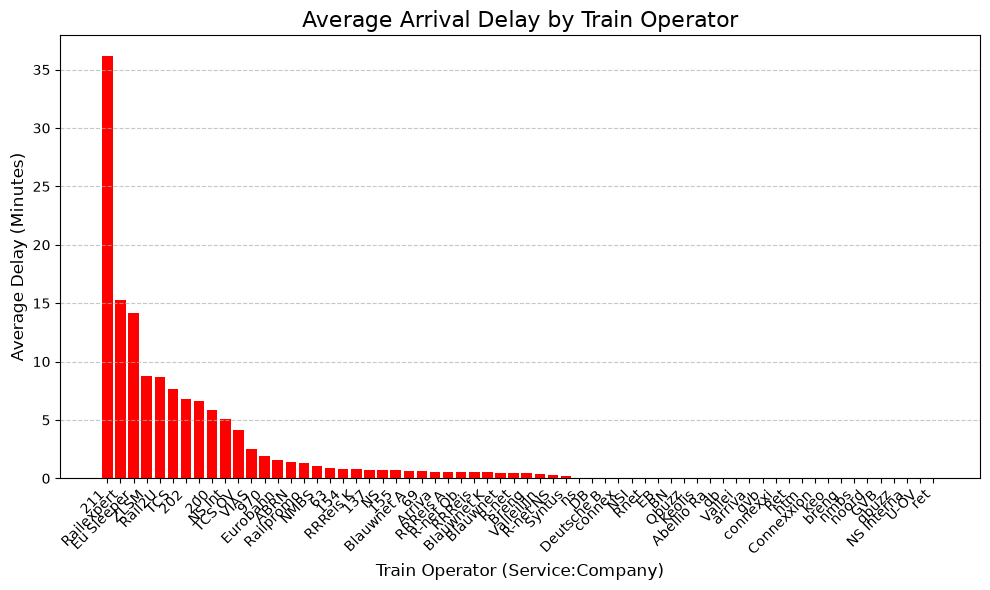

In [51]:
df_sorted = company_avg_delay.sort_values(by="avg_delay", ascending=False)

companies = df_sorted["Service:Company"]
avg_delays = df_sorted["avg_delay"]

plt.figure(figsize=(10, 6))

plt.bar(
    companies,
    avg_delays,
    color='red'
)

plt.title("Average Arrival Delay by Train Operator", fontsize=16)
plt.xlabel("Train Operator (Service:Company)", fontsize=12)
plt.ylabel("Average Delay (Minutes)", fontsize=12)

plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


<Axes: title={'center': 'Number of disruptions by year'}, xlabel='year'>

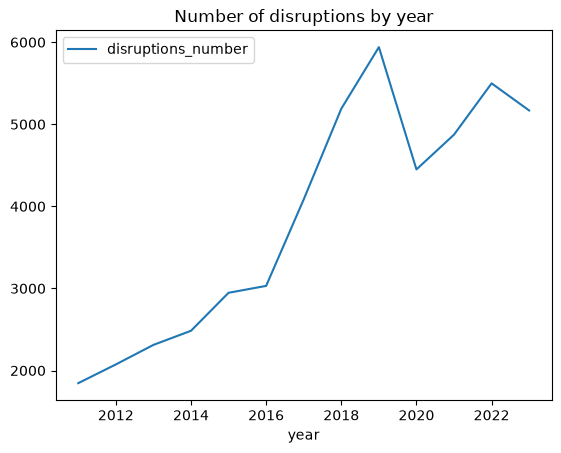

In [52]:
disruptions_by_year = db.sql("""
SELECT COUNT(*) AS disruptions_number,
       YEAR("start_time") AS year
FROM postgres_db.disruptions
GROUP BY year
ORDER BY year ASC
""").df()

disruptions_by_year.plot.line(
    x="year", y="disruptions_number", title="Number of disruptions by year"
)

<Axes: title={'center': 'Fraction of services canceled each year'}, xlabel='year'>

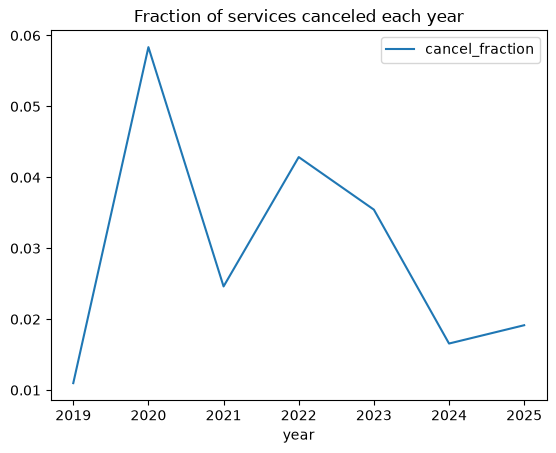

In [53]:
fraction_services_canceled_per_year = db.sql("""
SELECT
  YEAR("Service:Date") AS year,
  SUM(CASE WHEN "Service:Completely cancelled" = 'true' THEN 1 ELSE 0 END) * 1.0 /
  COUNT(*) AS cancel_fraction
FROM services
GROUP BY YEAR("Service:Date")
ORDER BY year ASC
""").df()

fraction_services_canceled_per_year.plot.line(
    x="year", y="cancel_fraction", title="Fraction of services canceled each year"
)